# Imports

In [1]:
# ---- Device: must run before anything imports jax ----
from devices import use_device
use_device("auto")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
# os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false") # If sharing GPU with other processes
os.environ.setdefault("XLA_PYTHON_CLIENT_MEM_FRACTION", "0.2") # If not set, JAX automatically grabs 75% of the GPU's total memory, which can be excessive
# os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip() #force deterministic computation on GPU
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
    wraparound_ratio_posthoc,
)
from model import (
    setup_model,
    make_orthogonal_poly_log_sed,
)
from data import (
    prepare_burst,
)
from run import (
    set_priors,
    run_fit,
    posthoc_samples,
)
from results import (
    save_run,
    to_idata,
)

from plotting import (
    plot_burst_TD, 
    plot_burst_FD,
    model_from_draw,
    plot_fit_TD,
    plot_fit_FD,
    plot_noise_window,
    to_time_domain,
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import arviz as az
import arviz_plots as azp
az.rcParams["plot.max_subplots"] = 300

import random

FRBayes: running on the GPU


/arc/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.2
gpu
[CudaDevice(id=0)]
local device count: 1


ImportError: cannot import name 'FD_marg_fullnormal_gaussianlikelihood' from 'likelihood' (/arc/home/hsiegel/FRBayes/src/likelihood.py)

# Setup

In [ ]:
from pathlib import Path

PROJECT  = Path("/arc/home/hsiegel/FRBayes")

# event_id = "22310619_BB" #Multi-pulse, 3 pulses
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# "22310619_BB"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "27687783_BB" #Multi-pulse, many
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=64,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

event_id = "22154974_BB" # Single-pulse, Broadband with scatter
data_path = PROJECT / "data" / f"event_{event_id}.npz"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

print("burst data shape =",burst.data_fd.shape)
plot_burst_TD(burst);                                          # data, in time
plot_burst_FD(burst);                                          # data, in Fourier space

In [3]:
!nvidia-smi

/usr/lib/python3.13/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Thu Nov  5 21:19:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H100 NVL                On  |   00000000:B1:00.0 Off |                   On |
| N/A   54C    P0             98W /  400W |                  N/A   |     N/A      Default |
|                                         |                        |              Enabled |
+-----------------------------------------+-----

# Run

In [3]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

# n_pulses = 5
# num_chains = 64
n_pulses = 3
num_chains = 64


target_accept_prob = 0.8
seed = 1
num_warmup = 500
num_samples = 200
progress_bar = True
repulsion_dict = {}
# repulsion_dict={"tau_scale":1, "x_min":1}


priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, shrink_sigma_npulses=True)
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, delta=dist.Uniform(-5.0, -3.0))
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, gamma_range=(-10.0, 30.0), beta_range=(-10.0, 30.0))


extend_duration = False # Padding against wraparound: off by default. Turn on when a pulse reaches the window edge.
# fit_fn = single_pulse_fn.extend_model_duration(burst, priors) if extend_duration else single_pulse_fn
fit_fn = single_pulse_fn.extend_model_duration(factor=2) if extend_duration else single_pulse_fn

mcmc = run_fit(burst, fit_fn, priors, FD_gaussianlikelihood, seed=seed,
               num_chains=num_chains, n_pulses=n_pulses, target_accept_prob=target_accept_prob,
               num_warmup=num_warmup, num_samples=num_samples, progress_bar=progress_bar,
               repulsion=repulsion_dict)#, shared_params=("DM", "tau_ref", "delta"))
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})
# idata = save_run(None, mcmc, burst, priors, data_path,
#                  single_pulse_fn=fit_fn, extra_samples=extra, event_id=event_id)


KeyboardInterrupt


KeyboardInterrupt



In [47]:
div = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["diverging"]).astype(bool)   # (chain, draw)
print("divergences per chain:", div.sum(axis=1))
# s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
# snr_on = 3.0                                                       # whatever you used
# checks = {
#     "closest-pair x":         s["toa_separation"].min(axis=-1),
#     "smallest A_snr":         s["A_snr"].min(axis=-1),
#     "pulse near snr_on (frac)": (np.abs(s["A_snr"] - snr_on) < 1.0).any(axis=-1).astype(float),
# }
# for name, v in checks.items():
#     print(f"{name:25s} divergent: {np.median(v[div]) if 'frac' not in name else v[div].mean():.2f}   "
#           f"others: {np.median(v[~div]) if 'frac' not in name else v[~div].mean():.2f}")

divergences per chain: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0 22  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  4  0  0 68  0  0  0  0  0  0  0  2]


In [48]:
steps = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])     # (chain, draw), after warmup
depth = np.ceil(np.log2(steps + 1)).astype(int)
max_depth = 10                                                                    # whatever the run used
for c in range(steps.shape[0]):
    print(f"chain {c}: median depth {np.median(depth[c]):.0f}   max {depth[c].max()}   "
          f"hit the limit {np.mean(steps[c] >= 2 ** max_depth - 1):.0%}   mean steps {steps[c].mean():.0f}")

chain 0: median depth 4   max 5   hit the limit 0%   mean steps 16
chain 1: median depth 4   max 6   hit the limit 0%   mean steps 20
chain 2: median depth 5   max 7   hit the limit 0%   mean steps 27
chain 3: median depth 4   max 5   hit the limit 0%   mean steps 16
chain 4: median depth 5   max 5   hit the limit 0%   mean steps 28
chain 5: median depth 8   max 8   hit the limit 0%   mean steps 255
chain 6: median depth 4   max 6   hit the limit 0%   mean steps 21
chain 7: median depth 5   max 7   hit the limit 0%   mean steps 32
chain 8: median depth 4   max 6   hit the limit 0%   mean steps 18
chain 9: median depth 4   max 5   hit the limit 0%   mean steps 17
chain 10: median depth 4   max 6   hit the limit 0%   mean steps 18
chain 11: median depth 7   max 8   hit the limit 0%   mean steps 161
chain 12: median depth 5   max 6   hit the limit 0%   mean steps 31
chain 13: median depth 4   max 5   hit the limit 0%   mean steps 15
chain 14: median depth 4   max 8   hit the limit 0%   me

In [49]:
ns = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])
print("leapfrogs per iteration, median per chain:", np.median(ns, axis=1), "  max:", ns.max())
print("step size per chain:", np.asarray(mcmc.last_state.adapt_state.step_size))

leapfrogs per iteration, median per chain: [ 15.  15.  31.  15.  31. 255.  15.  31.  15.  15.  15. 127.  31.  15.
  15.  15.  15.  15.  15.  15.  15. 255.  31.  15.  15.  47.  15.  15.
  15.  63. 255.  15.  15.  15.  15.  15.  63.  15.  15.  15. 255.  15.
  63.  15.  15. 127. 255.  15.  15.  15.  31.  15.  31.  15.  15.  15.
  15.  15.  79.  15.  31.  63.  15.  63.]   max: 255
step size per chain: [0.21772468 0.21103373 0.17535503 0.22985552 0.14274131 0.0057984
 0.20705526 0.1214463  0.19964516 0.21970049 0.22480103 0.02346857
 0.1252635  0.22731578 0.20786381 0.19717889 0.23372681 0.22806123
 0.21681392 0.21588218 0.21886693 0.01145272 0.1803909  0.20694268
 0.18839999 0.08070733 0.21348068 0.21747221 0.21211357 0.07381866
 0.01395402 0.19235818 0.19725136 0.20506944 0.22641414 0.2008275
 0.04789921 0.19548374 0.21689191 0.2229549  0.00546921 0.27797976
 0.08016758 0.23192245 0.20500915 0.02530872 0.01700997 0.21251564
 0.22944221 0.20620213 0.18141973 0.20899315 0.16728012 0.2081430

In [50]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,89.470,110.013,2.249,0.000,0.000
A[1],0.000,0.000,0.000,0.000,85.278,115.015,2.175,0.000,0.000
A[2],0.000,0.000,0.000,0.000,88.519,119.229,2.029,0.000,0.000
A_snr[0],39.851,23.533,1.321,60.474,83.496,82.651,2.240,2.880,1.215
A_snr[1],38.597,20.070,5.113,60.018,77.587,131.814,2.684,2.455,1.297
A_snr[2],29.467,21.913,5.312,59.757,82.929,136.541,2.271,2.681,0.697
DM[0],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM[1],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM[2],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM_shared,-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001


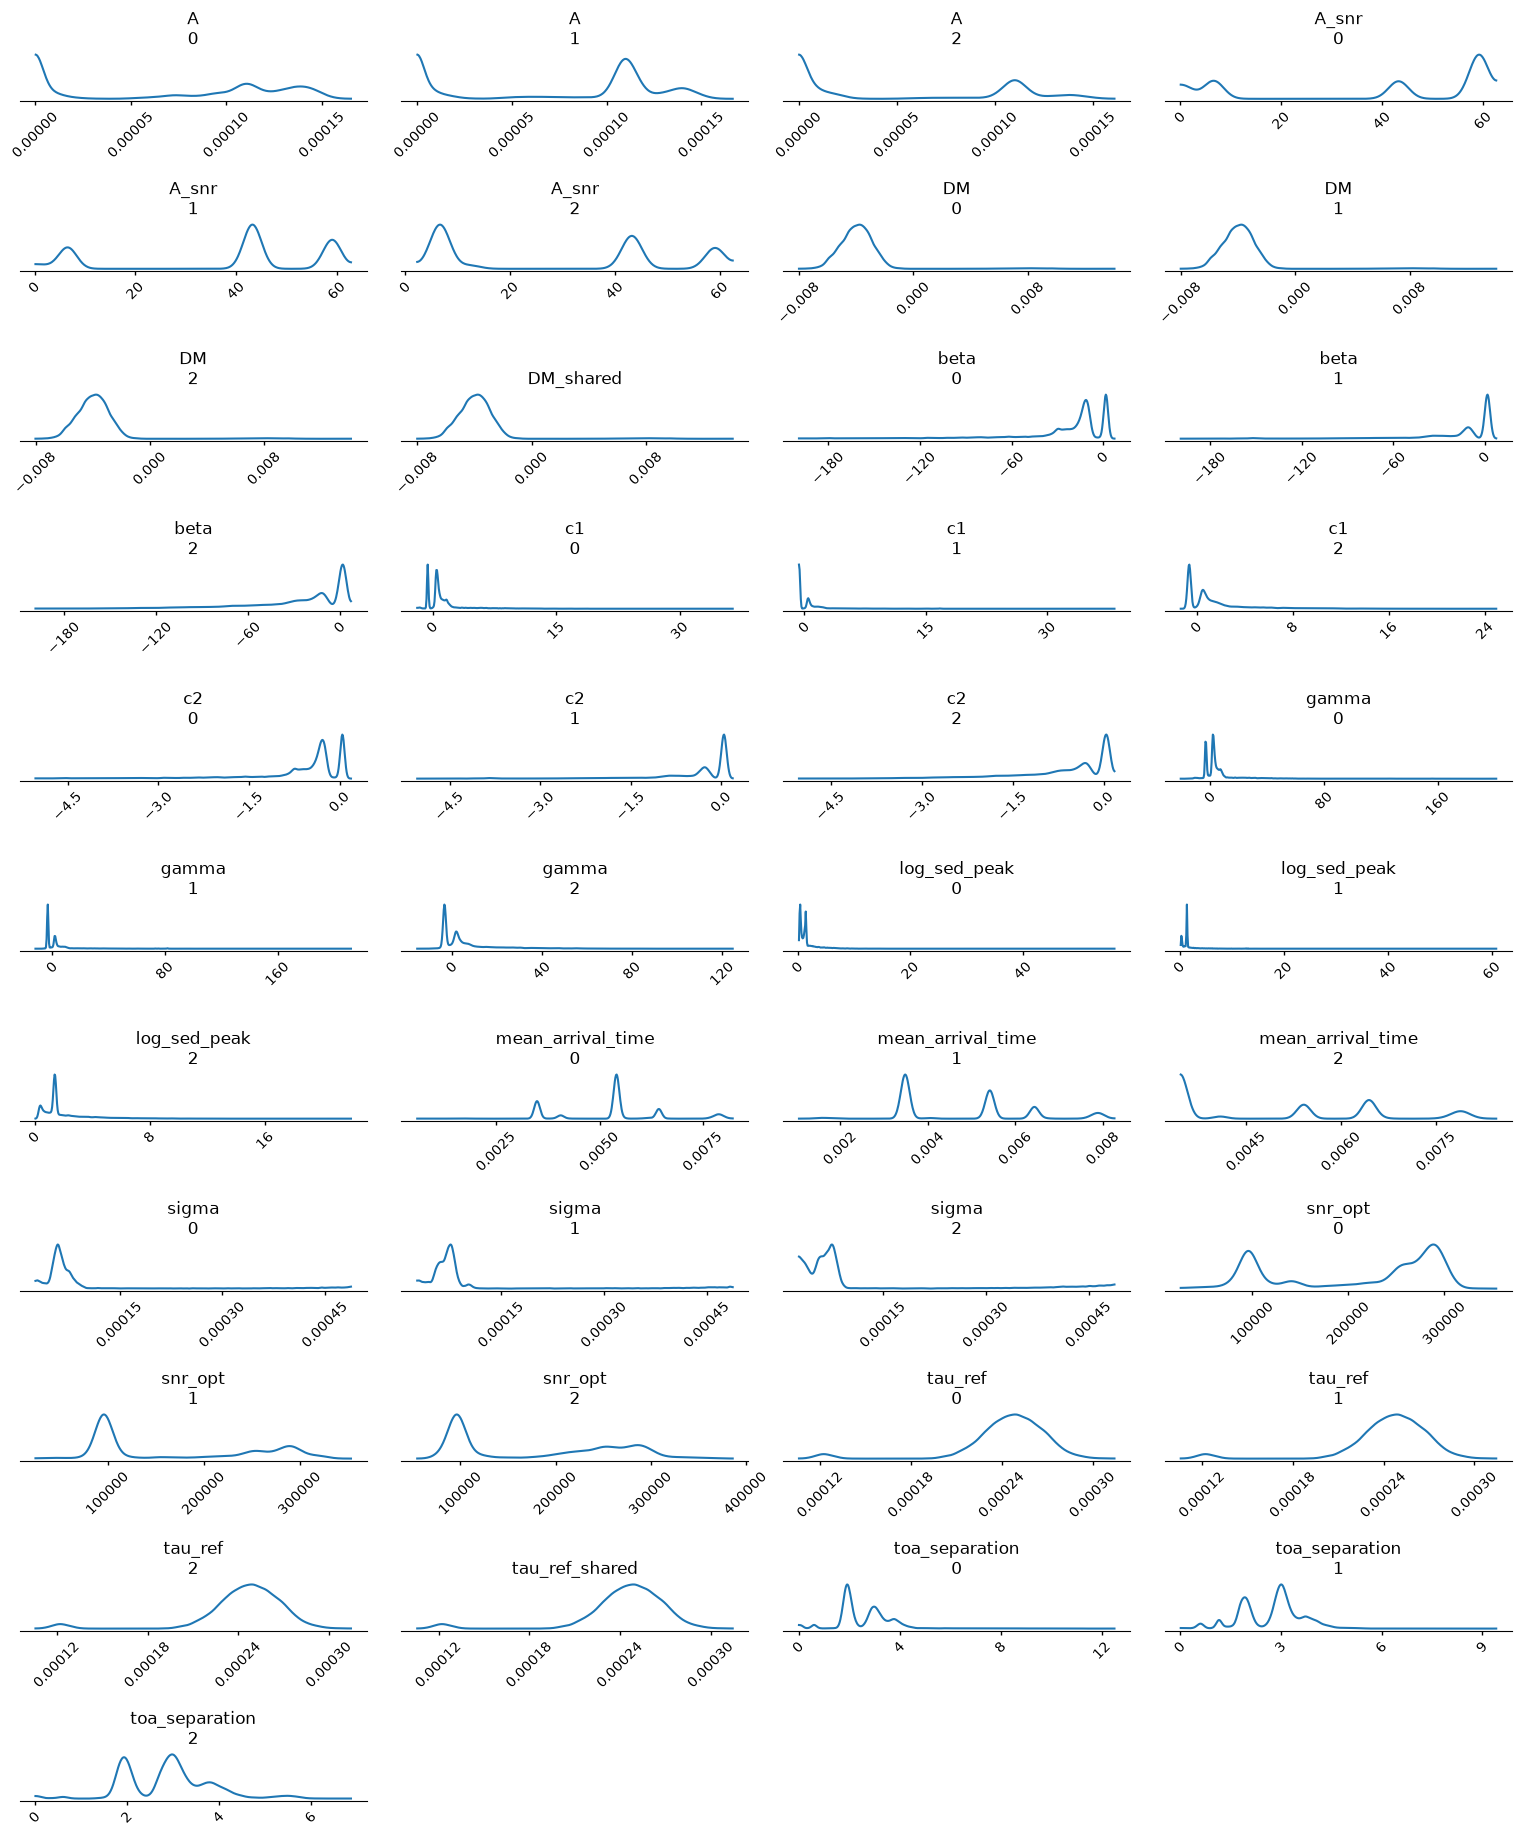

In [51]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

In [52]:
# import warnings

# warnings.filterwarnings(
#     "ignore",
#     message="Explicitly requested dtype.*is not available",
#     category=UserWarning,
# )

# azp.plot_trace(mcmc_data)

# # 2. Clean up x-axis tick clutter across all generated subplots
# for ax in plt.gcf().axes:
#     ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
#     ax.tick_params(axis="x", rotation=45)

# plt.tight_layout()
# plt.show()

In [53]:
pe = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
active = s["A_snr"] > 3.0
for c in np.argsort(pe.mean(axis=1)):                      # best (lowest -log post) first
    t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)
    print(f"chain {c}: -log post {pe[c].mean():9.1f} ± {pe[c].std():4.1f}   "
          f"active {active[c].sum(-1).mean():.1f}   t [ms] {np.round(np.sort(t) * 1e3, 2)}   "
          f"A_snr {np.round(np.median(s['A_snr'][c], axis=0), 1)}")

chain 41: -log post    3734.4 ±  2.5   active 3.0   t [ms] [3.52 4.09 5.46]   A_snr [43.3 58.5 12.3]
chain 39: -log post    3734.7 ±  2.6   active 3.0   t [ms] [3.52 4.09 5.46]   A_snr [43.3 58.6 12.5]
chain 45: -log post    3752.9 ±  2.6   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [59.1 42.9  6.9]
chain 7: -log post    3753.3 ±  3.2   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [59.1 43.1  6.7]
chain 28: -log post    3753.4 ±  2.9   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [ 6.8 42.9 59.1]
chain 54: -log post    3753.5 ±  2.7   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [ 6.9 59.1 43. ]
chain 6: -log post    3753.5 ±  2.8   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [ 6.8 42.9 59. ]
chain 58: -log post    3753.5 ±  2.9   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [59.  43.1  6.9]
chain 19: -log post    3753.5 ±  3.0   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [59.   6.8 42.8]
chain 35: -log post    3753.5 ±  3.0   active 3.0   t [ms] [3.49 5.41 6.44]   A_snr [59.   6.

/tmp/ipykernel_19318/2849936320.py:5: RuntimeWarning: All-NaN slice encountered
  t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)


In [54]:
key = jax.random.PRNGKey(7)

In [64]:
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})


sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


draw 11057 (chain 55)
chain 55, draw 11057:  A_snr [58.8  6.2 41.9]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


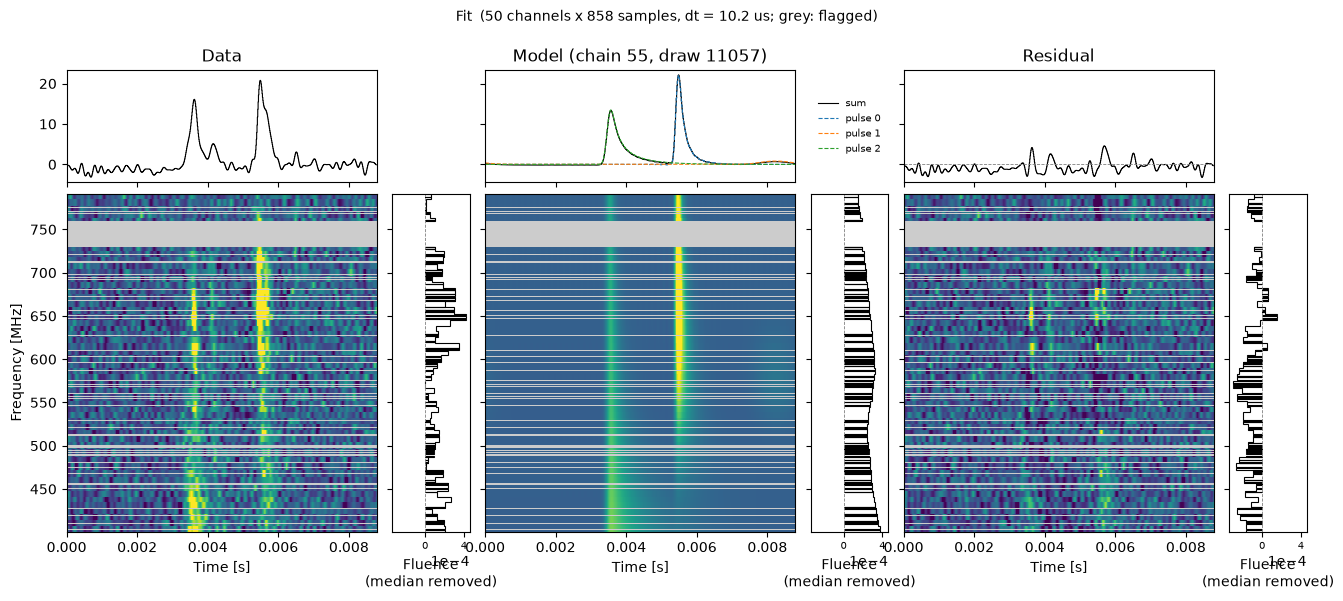

whitened residual sd: 1.182  (expect 1)


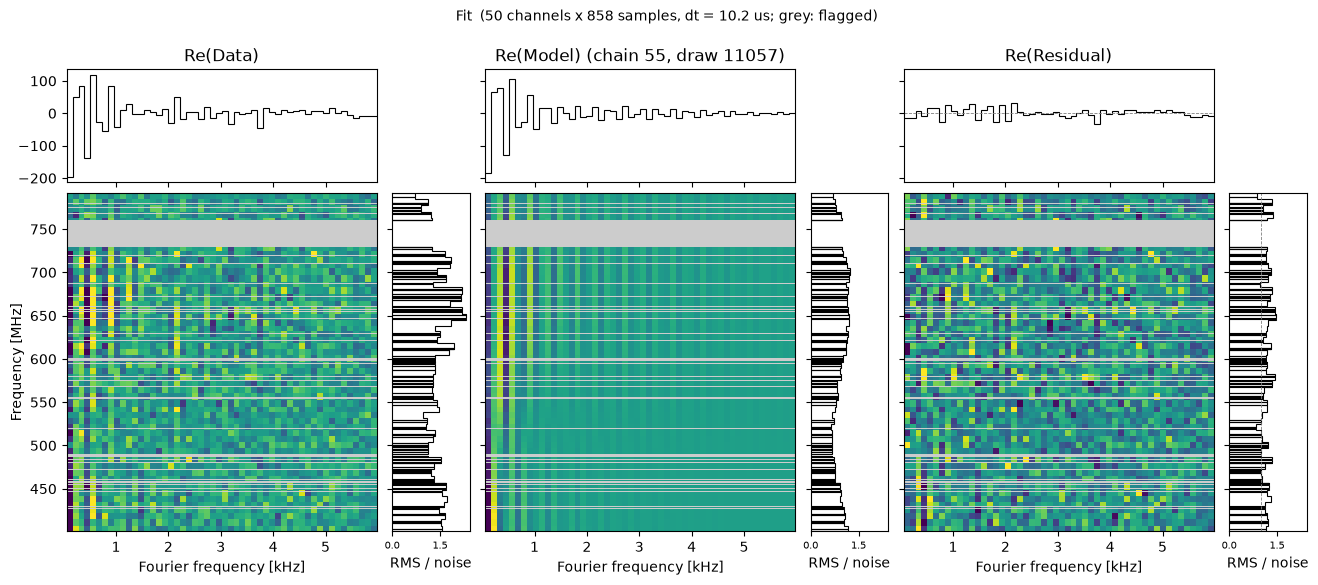

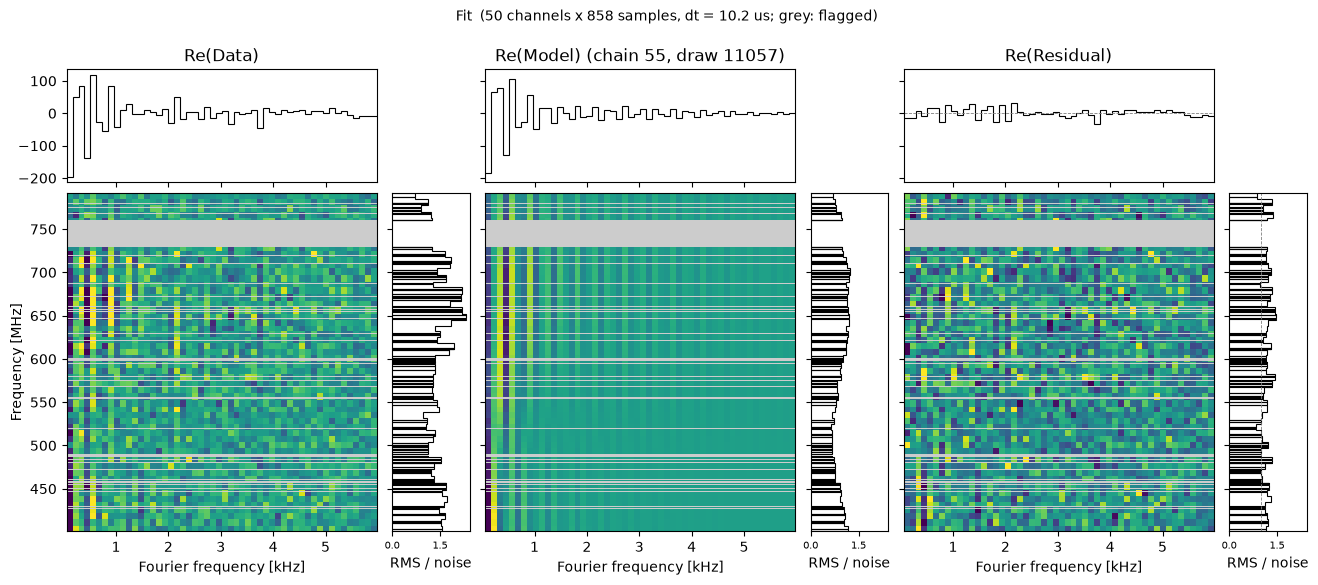

In [67]:
chain = 55                     # the chain to draw from
n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
print(f"draw {draw_idx} (chain {chain})")

print(f"chain {chain}, draw {draw_idx}:  A_snr", np.round(np.asarray(samples["A_snr"][draw_idx]).reshape(-1), 1))

M_FD, M_FD_pulses = model_from_draw(fit_fn, samples, draw_idx)
plot_fit_TD(burst, M_FD, M_FD_pulses, title_model=f"Model (chain {chain}, draw {draw_idx})")
plot_fit_FD(burst, M_FD, title_model=f"Re(Model) (chain {chain}, draw {draw_idx})")

draw 1169 (chain 5)
chain 5, draw 1169:  A_snr [59.4 43.6  6.4]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


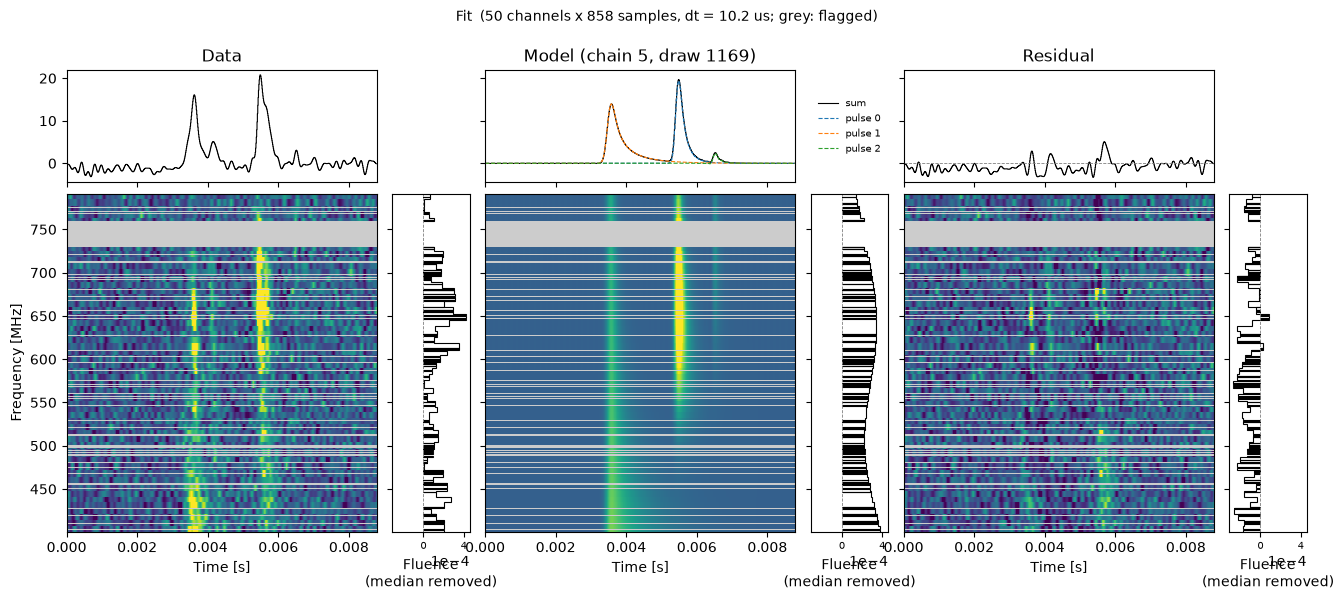

whitened residual sd: 1.190  (expect 1)


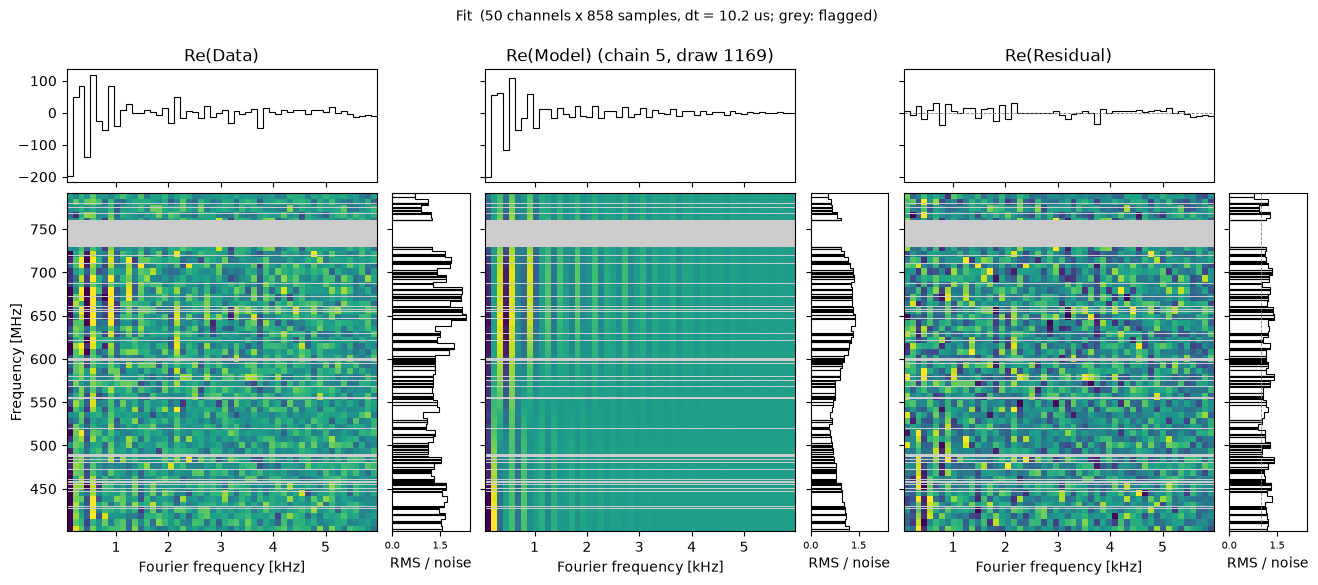

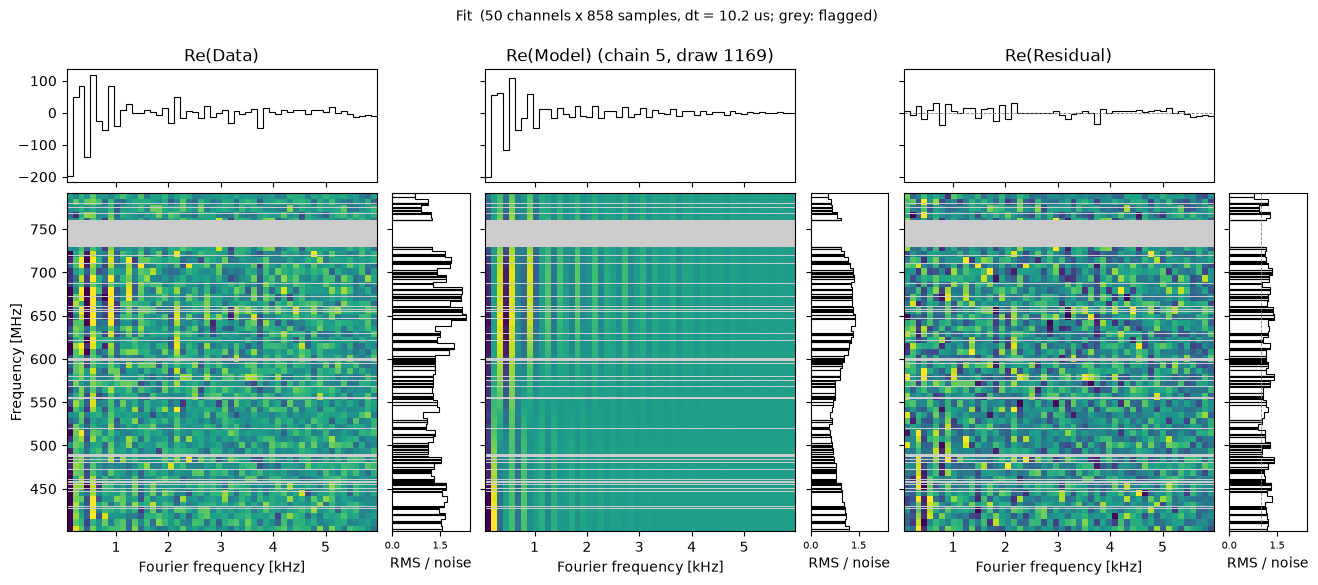

In [57]:
chain = 5                       # the chain to draw from
n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
print(f"draw {draw_idx} (chain {chain})")

print(f"chain {chain}, draw {draw_idx}:  A_snr", np.round(np.asarray(samples["A_snr"][draw_idx]).reshape(-1), 1))

M_FD, M_FD_pulses = model_from_draw(fit_fn, samples, draw_idx)
plot_fit_TD(burst, M_FD, M_FD_pulses, title_model=f"Model (chain {chain}, draw {draw_idx})")
plot_fit_FD(burst, M_FD, title_model=f"Re(Model) (chain {chain}, draw {draw_idx})")

noise window: first 796 of 3983 samples (to 8.15 ms)
  profile mean over the last third of the window: +8.22 standard errors (emission leaking in shows as clearly positive)
  profile sd in the window: 1.06   in the last 20% of the segment: 1.17   (expect 1)


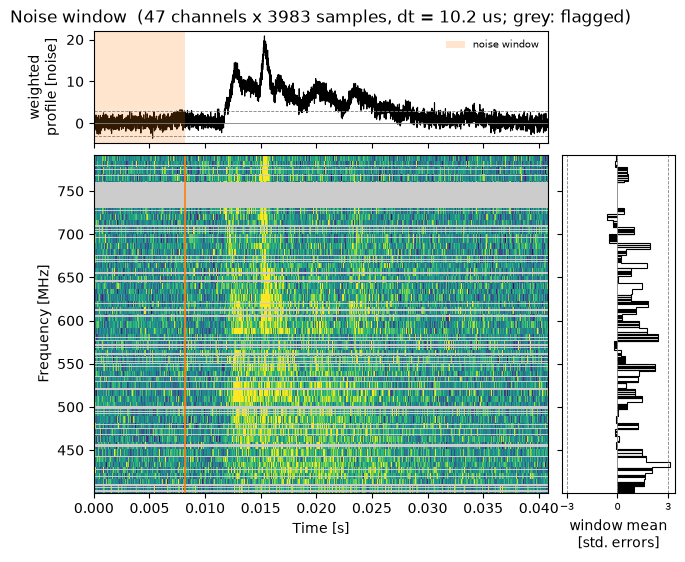

In [7]:
fig = plot_noise_window(burst)

In [59]:
# from postprocess import order_pulses
# samples = order_pulses(mcmc.get_samples(group_by_chain=True))   # or mcmc.get_samples()

In [60]:
# samples

In [61]:
# chain = 12                                                           # the chain to test
# n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
# draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
# M_FD, _ = model_from_draw(fit_fn, samples, draw_idx)
# print(f"chain {chain}, draw {draw_idx}")

R = np.asarray(burst.data_fd) - np.asarray(M_FD)
r = np.asarray(to_time_domain(burst, jnp.asarray(R))) / np.asarray(burst.sigma_noise_td).reshape(-1, 1)
w = np.asarray(burst.channel_weights)
prof = np.tensordot(np.sqrt(w), r, axes=(0, 0))                     # channel-weighted residual profile
prof /= prof[: burst.n_noise_bins].std()                             # unit variance off-pulse, cancelling noise-level errors

K = 20                                                               # window, a few pulse widths in samples
excess = np.convolve(prof ** 2 - 1.0, np.ones(K), mode="valid")      # SNR^2 of residual structure per window
i = int(np.argmax(excess))
print(f"residual SNR {np.sqrt(max(excess[i], 0)):.1f} in the window starting {burst.times[i] * 1e3:.2f} ms  (threshold 10)")

residual SNR 31.1 in the window starting 5.61 ms  (threshold 10)


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import arviz_plots as azp
from arviz_base import from_dict

# 1. pool within modes, stack between modes
samples = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}   # (chains, draws, ...)
log_lik = pointwise_log_lik(burst, single_pulse_fn, samples, thin=1)
posterior, info = combine_chains(samples, log_lik)        # prints the modes, their weights and draws
print("draws per chain:", dict(enumerate(np.bincount(info["chain"], minlength=len(log_lik)))))

# 2. marginals of the combined posterior
post = {}
for k in ("mean_arrival_time", "sigma", "tau_ref", "DM", "A_snr", "gamma", "beta", "c1", "c2"):
    if k not in posterior:
        continue
    v = np.asarray(posterior[k])
    if v.ndim == 2 and np.allclose(v, v[:, :1]):           # shared parameter, stored once per pulse
        v = v[:, 0]
    post[k] = v[None]                                        # chain axis of length 1
azp.plot_dist(from_dict({"posterior": post}), stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
    for collection in list(ax.collections):
        collection.remove()
plt.tight_layout()
plt.subplots_adjust(wspace=0.1, hspace=2.5)
plt.draw()

ValueError: mode_weights='peak' needs potential_energy: mcmc.get_extra_fields(group_by_chain=True)['potential_energy'].

In [ ]:
import numpy as np
from postprocess import excess_power_search
from plotting import model_from_draw

epsilon, n_test = 0.2, 10
rng = np.random.default_rng(0)
for d in rng.choice(len(posterior["mean_arrival_time"]), n_test, replace=False):
    M_FD, M_FD_pulses = model_from_draw(single_pulse_fn, posterior, d)
    ep = excess_power_search(burst, np.asarray(M_FD), epsilon=epsilon, verbose=False)
    t = ep["tiles"][0]
    print(f"draw {d}: {'ADD' if ep['add_pulse'] else 'stop'}  p={ep['p']:.2g}  "
          f"unexplained SNR {t['snr_unexplained']:.1f} at {t['t_range'][0]*1e3:.1f}-{t['t_range'][1]*1e3:.1f} ms, "
          f"{t['channel_range'][0]:.0f}-{t['channel_range'][1]:.0f} MHz")

In [ ]:
import importlib, postprocess, plotting
importlib.reload(postprocess); importlib.reload(plotting)
from postprocess import excess_power_search
from plotting import model_from_draw, plot_residual_tiles

d = 0                                                         # stacked draw to test
M_FD, M_FD_pulses = model_from_draw(single_pulse_fn, posterior, d)
ep = excess_power_search(burst, np.asarray(M_FD), epsilon=0.2)
plot_residual_tiles(burst, M_FD, ep)

# 1 vs n pulse comparisons

In [ ]:
# import importlib, postprocess, plotting
# importlib.reload(postprocess); importlib.reload(plotting)
# from postprocess import excess_power_search
# from plotting import plot_residual_tiles

# ep = excess_power_search(burst, fits[2]["M"])
# plot_residual_tiles(burst, fits[2]["M"], ep)

In [ ]:
# for i, t in enumerate(ep["tiles"], 1):
#     print(i, np.round(np.array(t["t_range"]) * 1e3, 2), t["channel_range"],
#           "Fourier band (kHz):", np.round(np.array(t["fourier_band"]) / 1e3, 1),
#           "resolution:", t["resolution"], "cells:", t["n_cells"], "SNR:", round(t["snr_unexplained"], 1))

## running power law

prior being set with bounds:
sigma_min = 2.8220349260529353e-05 
sigma_max = 0.0005614933299208739 
tau_ref_min = 0.0 
tau_ref_max = 0.0010824326633166927
iterative_pulse_fit: snr_min 8 (delta ELPD threshold 32), minimum box width 5 channels, up to 5 pulses
prior being set with bounds:
sigma_min = 2.8220349260529353e-05 
sigma_max = 0.0005614933299208739 
tau_ref_min = 0.0 
tau_ref_max = 0.0010824326633166927
mean_arrival_time: Uniform(low=0, high=0.00335872)
DM: Uniform(low=-0.0898636, high=0.0898636)
sigma: LogUniform(low=2.82203e-05, high=0.000561493)
tau_ref: Uniform(low=0, high=0.00108243)
A_snr: HalfNormal(scale=100)
gamma: Uniform(low=-10, high=200)
beta: Uniform(low=-200, high=10)
run_fit seed: 2
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [01:45<00:00,  6.61it/s]


group_chains: 64 chains -> 2 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], largest R-hat within 1.061
  mode 1: chains [12]
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.953), 12600 draws from 63 chain(s)
  mode 1: peak log post -16291.0, mean log-lik -16269.6, weight 0.000 (stacking would give 0.047), 0 draws from 1 chain(s)
combine_chains: 12600 draws in all
Residual test (tolerating 20% model error): ADD A PULSE (p = 8.6e-110 after 14322 boxes; min_snr 8)
  1797 boxes significant on their own, making 4 separate feature(s):
    0.98-1.68 ms, 544-680 MHz: unexplained SNR 30.3 (residual 30.9, model 30.3), centre 1.24 ms, width 0.15 ms
    1.26-2.11 ms, 54

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [02:43<00:00,  4.29it/s]


group_chains: 64 chains -> 4 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 11, 12, 13, 14, 15, 16, 18, 19, 20, 23, 24, 25, 27, 28, 29, 32, 33, 34, 35, 36, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 51, 52, 53, 54, 55, 56, 58, 60, 62, 63], largest R-hat within 1.103
  mode 1: chains [9, 10, 21, 26, 30, 31, 57, 59], largest R-hat within 1.036
  mode 2: chains [61]
  mode 3: chains [17, 22, 37, 38, 50], largest R-hat within 1.035
  modes weighted by peak posterior:
  mode 0: peak log post -0.0, mean log-lik +0.0, weight 0.495 (stacking would give 0.386), 196 draws from 50 chain(s)
  mode 1: peak log post -5.9, mean log-lik -3.2, weight 0.001 (stacking would give 0.480), 1 draws from 8 chain(s)
  mode 2: peak log post +0.0, mean log-lik -11.4, weight 0.504 (stacking would give 0.000), 200 draws from 1 chain(s)
  mode 3: peak log post -52.4, mean log-lik -48.4, weight 0.000 (stacking would give 0.134), 0 draws from 5 chain(s)
combine_chains: 39

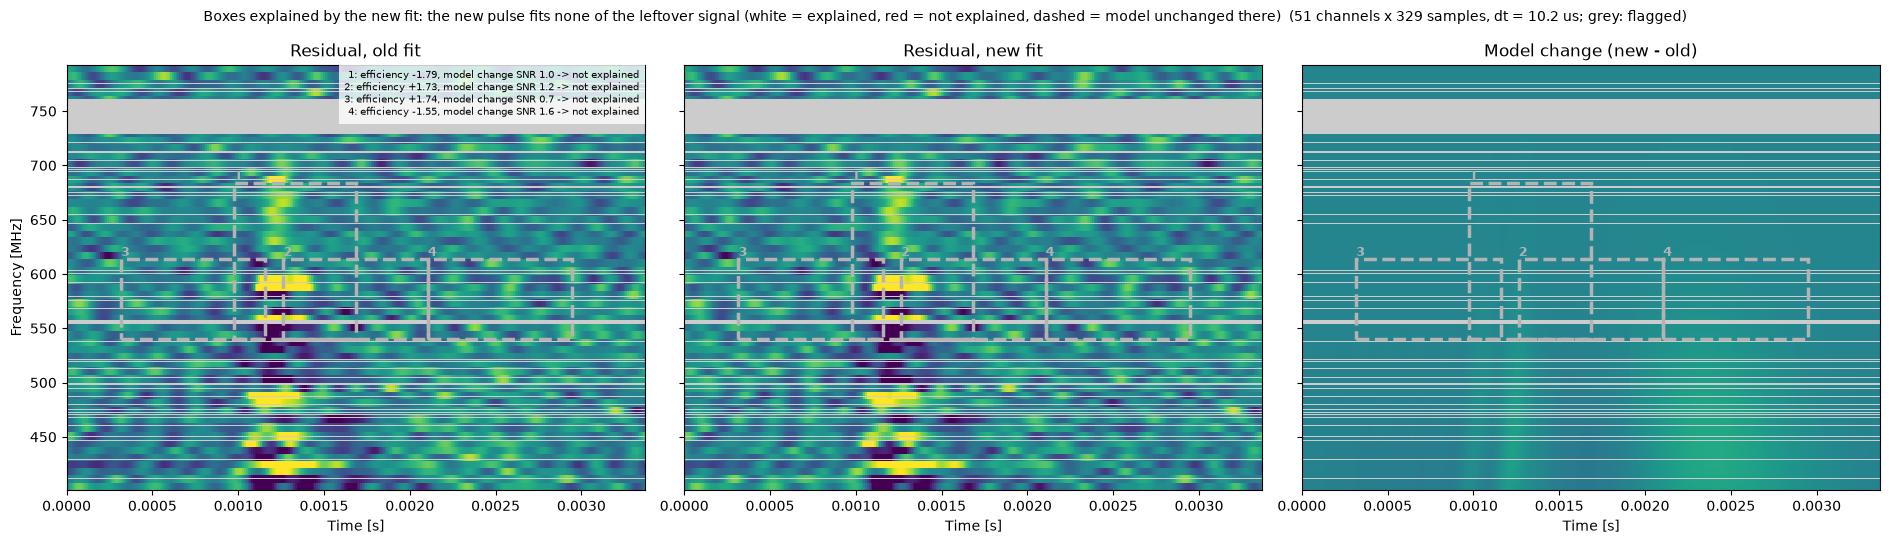

1 -> 2 pulses: delta ELPD = 20.6 (need 32.0), explains leftover signal: False -> reject
final: 1 pulses (2-pulse fit rejected: it explains no flagged leftover signal and delta ELPD 20.6 < 32)
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


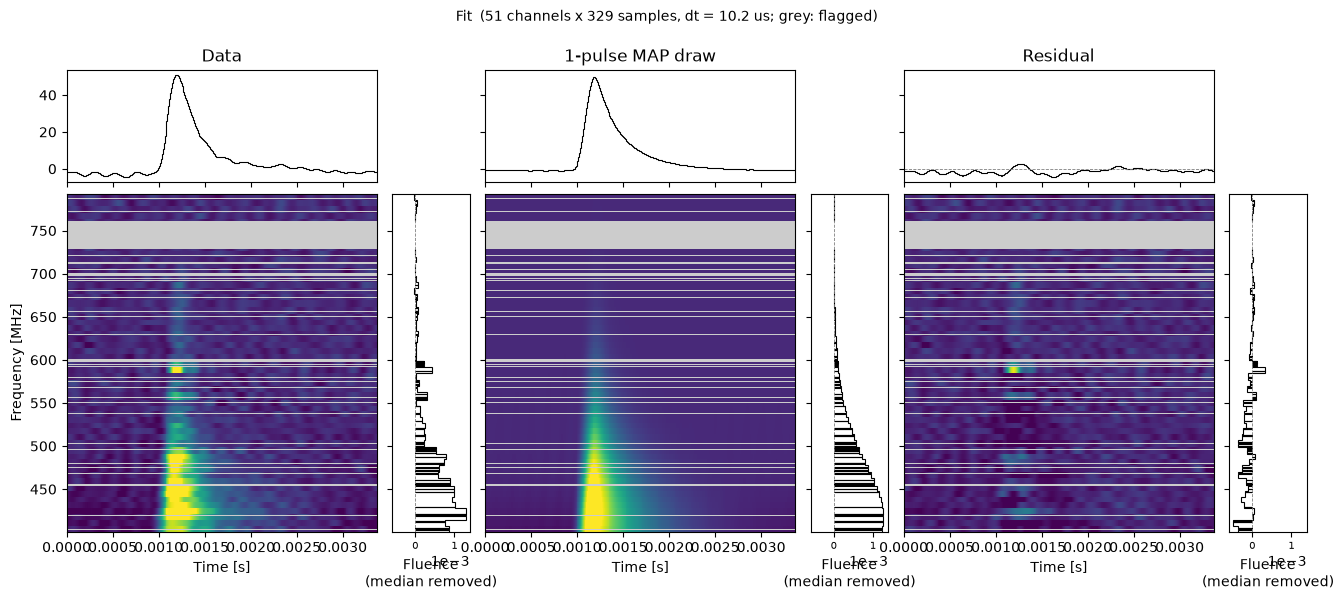

In [5]:
import numpyro.distributions as dist
from model import running_power_law_log_sed
from run import (
    iterative_pulse_fit,
)


constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
    "det_response": 1.0,           # beam response, set to 1 if not used
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,      # ln F = gamma x + beta x^2, no orthogonal basis
    fourier_freqs=burst.fourier_freqs,
)

result = iterative_pulse_fit(
    burst, single_pulse_fn,
    snr_min=8.0,          # one detection SNR: search, box check, and delta ELPD >= snr_min^2 / 2
    n_max=5,              # largest number of pulses tried
    num_chains=64,
    seed=2,
    plot_steps=True,      # draw each step's box check (False to skip)
    prior_kwargs=dict(gamma=dist.Uniform(-10.0, 200.0),     # same box the c1, c2 bounds come from
                      beta=dist.Uniform(-200.0, 10.0)),
    repulsion={},         # passed to the likelihood
)

# the kept fit, drawn at its maximum a posteriori draw
n = result["n_pulses"]
p = result["fit"]["map"]
M, M_pulses = model_from_draw(single_pulse_fn, {k: np.asarray(v)[None] for k, v in p.items()}, 0)
plot_fit_TD(burst, M, M_pulses, title_model=f"{n}-pulse MAP draw");

# # save the kept fit
# idata = save_run(
#     out_path, result["fit"]["mcmc"], burst, result["fit"]["priors"], data_path,
#     single_pulse_fn=single_pulse_fn, event_id=event_id,
#     dm_dedispersion=dm_dedispersion, dedispersion_ref_freq=dedispersion_ref_freq,
#     n_pulses=n, itfit_snr_min=result["snr_min"], itfit_stop=result["stop"],
# )

## orthog SED

prior being set with bounds:
sigma_min = 2.8220349260529353e-05 
sigma_max = 0.0005614933299208739 
tau_ref_min = 0.0 
tau_ref_max = 0.0010824326633166927
prior being set with bounds:
c1_min = -4.403665 
c1_max = 20.124588 
c2_min = -3.1836112 
c2_max = 0.15918055
iterative_pulse_fit: snr_min 8 (delta ELPD threshold 32), minimum box width 5 channels, up to 5 pulses
prior being set with bounds:
sigma_min = 2.8220349260529353e-05 
sigma_max = 0.0005614933299208739 
tau_ref_min = 0.0 
tau_ref_max = 0.0010824326633166927
prior being set with bounds:
c1_min = -4.403665 
c1_max = 20.124588 
c2_min = -3.1836112 
c2_max = 0.15918055
mean_arrival_time: Uniform(low=0, high=0.00335872)
DM: Uniform(low=-0.0898636, high=0.0898636)
sigma: LogUniform(low=2.82203e-05, high=0.000561493)
tau_ref: Uniform(low=0, high=0.00108243)
c1: Uniform(low=-4.40367, high=20.1246)
c2: Uniform(low=-3.18361, high=0.159181)
A_snr: HalfNormal(scale=100)
run_fit seed: 2
sampling the amplitude as A_snr (SNR units)
sampling

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [01:52<00:00,  6.23it/s]


group_chains: 64 chains -> 2 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 63], largest R-hat within 1.085
  mode 1: chains [62]
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.756), 12600 draws from 63 chain(s)
  mode 1: peak log post -180.2, mean log-lik -175.4, weight 0.000 (stacking would give 0.244), 0 draws from 1 chain(s)
combine_chains: 12600 draws in all
Residual test (tolerating 20% model error): ADD A PULSE (p = 3.8e-109 after 14322 boxes; min_snr 8)
  1797 boxes significant on their own, making 4 separate feature(s):
    0.98-1.68 ms, 544-680 MHz: unexplained SNR 30.2 (residual 30.8, model 30.4), centre 1.24 ms, width 0.15 ms
    1.26-2.11 ms, 544-61

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [02:23<00:00,  4.89it/s]


group_chains: 64 chains -> 4 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 32, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 53, 54, 55, 56, 57, 59, 61, 62, 63], largest R-hat within 1.067
  mode 1: chains [15, 16, 35, 49, 52, 60], largest R-hat within 1.037
  mode 2: chains [17]
  mode 3: chains [31, 58], largest R-hat within 1.015
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.377), 11000 draws from 55 chain(s)
  mode 1: peak log post -8.1, mean log-lik -3.2, weight 0.000 (stacking would give 0.482), 0 draws from 6 chain(s)
  mode 2: peak log post -11.2, mean log-lik -13.6, weight 0.000 (stacking would give 0.015), 0 draws from 1 chain(s)
  mode 3: peak log post -53.5, mean log-lik -48.2, weight 0.000 (stacking would give 0.126), 0 draws from 2 chain(s)
combine_chains: 1

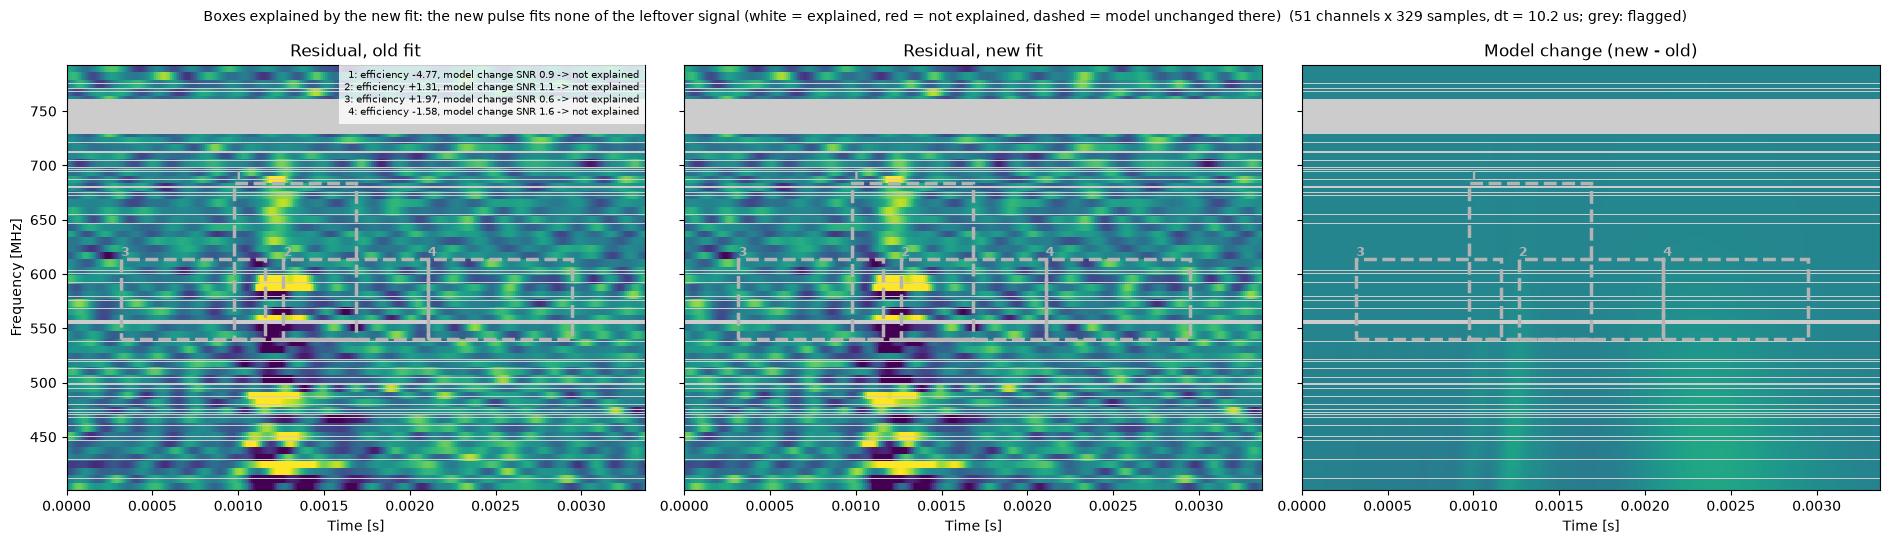

1 -> 2 pulses: delta ELPD = 50.0 (need 32.0), explains leftover signal: False -> reject
final: 1 pulses (2-pulse fit rejected: it explains no flagged leftover signal)
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


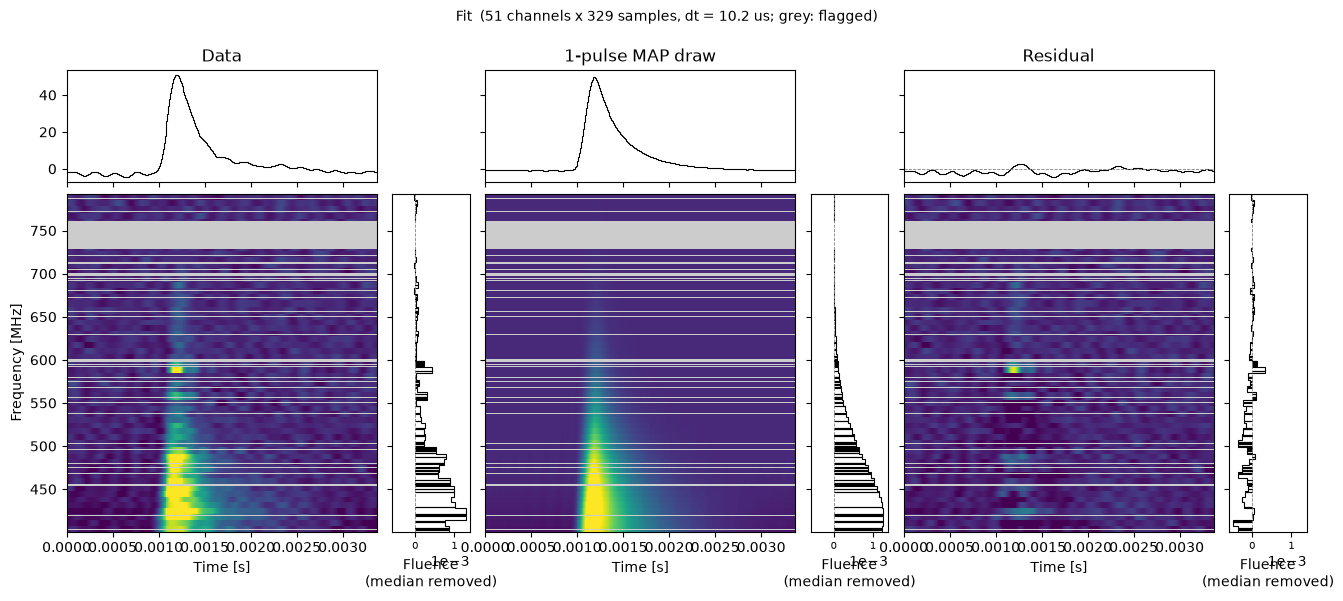

In [7]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
    "det_response": 1.0  # beam response, set to 1 if not used
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

result_orthog = iterative_pulse_fit(
    burst, single_pulse_fn,
    snr_min=8.0,          # one detection SNR: search, box check, and delta ELPD >= snr_min^2 / 2
    n_max=5,              # largest number of pulses tried
    num_chains=64,
    seed=2,
    plot_steps=True,      # draw each step's box check (False to skip)
    repulsion={},         # passed to the likelihood
)

# the kept fit, drawn at its maximum a posteriori draw
n = result_orthog["n_pulses"]
p = result_orthog["fit"]["map"]
M, M_pulses = model_from_draw(single_pulse_fn, {k: np.asarray(v)[None] for k, v in p.items()}, 0)
plot_fit_TD(burst, M, M_pulses, title_model=f"{n}-pulse MAP draw");

# # save the kept fit
# idata = save_run(
#     out_path, result["fit"]["mcmc"], burst, result["fit"]["priors"], data_path,
#     single_pulse_fn=single_pulse_fn, event_id=event_id,
#     dm_dedispersion=dm_dedispersion, dedispersion_ref_freq=dedispersion_ref_freq,
#     n_pulses=n, itfit_snr_min=result["snr_min"], itfit_stop=result["stop"],
# )

In [10]:
from postprocess import order_pulses
import pandas as pd

N = 1            # compare the fits with this many pulses; both runs must have reached it
PARAMS = ["gamma", "beta", "A_snr", "mean_arrival_time", "sigma", "tau_ref_shared", "DM_shared"]

def main_mode(result, n):
    """Summary of the highest-weight mode's chains of the n-pulse fit, with ESS per 1000 leapfrog steps."""
    fit = result["fits"][n]
    chains = list(fit["info"]["modes"][int(np.argmax(fit["info"]["weights"]))])
    raw = order_pulses({k: np.asarray(v) for k, v in fit["mcmc"].get_samples(group_by_chain=True).items()},
                       active_snr=None, verbose=False)
    names = [k for k in PARAMS if k in raw]
    dt = az.from_dict({"posterior": {k: raw[k][chains] for k in names}},
                      dims={k: ["pulse"] for k in names if raw[k].ndim == 3})
    s = az.summary(dt, kind="all", round_to="none")
    steps = np.asarray(fit["mcmc"].get_extra_fields(group_by_chain=True)["num_steps"])[chains].sum()
    s["ess_bulk_per_1k_steps"] = s["ess_bulk"] / steps * 1e3
    print(f"{len(chains)} chains in the main mode, {steps / len(chains) / raw['A_snr'].shape[1]:.1f} leapfrog steps per draw")
    return s[["mean", "sd", "r_hat", "ess_bulk", "ess_bulk_per_1k_steps"]]

cmp = pd.concat({"orthogonal": main_mode(result_orthog, N), "gamma_beta": main_mode(result, N)}, axis=1)
cmp["mean_shift_in_sd"] = ((cmp["orthogonal", "mean"] - cmp["gamma_beta", "mean"])
                           / np.hypot(cmp["orthogonal", "sd"], cmp["gamma_beta", "sd"]))
cmp["ess_ratio_orth_over_gb"] = cmp["orthogonal", "ess_bulk_per_1k_steps"] / cmp["gamma_beta", "ess_bulk_per_1k_steps"]
cmp

63 chains in the main mode, 21.4 leapfrog steps per draw
63 chains in the main mode, 21.7 leapfrog steps per draw


orthogonal                                    \
                            mean        sd     r_hat      ess_bulk   
gamma[0]               -5.129782  0.080771  1.002572  13790.393149   
beta[0]               -13.815543  0.778110  1.003934  10340.556796   
A_snr[0]              181.641937  0.998882  1.005205  13188.383690   
mean_arrival_time[0]    0.001084  0.000001  1.002828  12400.838778   
sigma[0]                0.000055  0.000001  1.006579  10254.919445   
tau_ref_shared          0.000349  0.000005  1.004844  10514.371894   
DM_shared              -0.007046  0.000259  1.005381  12836.836034   

                                            gamma_beta                      \
                     ess_bulk_per_1k_steps        mean        sd     r_hat   
gamma[0]                         51.171049   -5.130361  0.080300  1.005726   
beta[0]                          38.369982  -13.811633  0.778726  1.003706   
A_snr[0]                         48.937215  181.646790  1.002670  1.006886   
mean_arrival_time[0]             46.014927    0.001084  0.000001  1.003181   
sigma[0]                         38.052214    0.000055  0.000001  1.003974   
tau_ref_shared                   39.014946    0.000349  0.000005  1.003798   
DM_shared                        47.632752   -0.007046  0.000251  1.005672   

                                                         mean_shift_in_sd  \
                          ess_bulk ess_bulk_per_1k_steps                    
gamma[0]              13591.120258             49.617115         0.005083   
beta[0]               12808.982821             46.761766        -0.003552   
A_snr[0]              16401.094301             59.875490        -0.003428   
mean_arrival_time[0]  13463.160077             49.149971         0.003755   
sigma[0]              12977.308806             47.376273         0.004258   
tau_ref_shared        13396.603813             48.906994        -0.001842   
DM_shared             15025.615623             54.854029        -0.000877   

                     ess_ratio_orth_over_gb  
                                             
gamma[0]                           1.031319  
beta[0]                            0.820542  
A_snr[0]                           0.817316  
mean_arrival_time[0]               0.936215  
sigma[0]                           0.803191  
tau_ref_shared                     0.797738  
DM_shared                          0.868355

# Computational diagnostics

In [ ]:
print("peak Memory usage in GB",jax.devices()[0].memory_stats()["peak_bytes_in_use"] / 1e9)